# AgroVisión
## Sistema inteligente de detección, conteo, estimación de tamaño y clasificación de madurez de frutos mediante visión computacional estereoscópica

**Herramientas:** Python 3 · OpenCV · NumPy · Pandas · Matplotlib · Scikit-learn

**Objetivo general.** Desarrollar un sistema de visión computacional con Python y OpenCV que detecte, cuente, estime el tamaño y clasifique el estado de maduración de frutos (tomate, banano, ...) mediante procesamiento digital de imágenes y visión estereoscópica.

**Perfiles de fruta.** Todo lo que depende de la fruta —clases de color, etapas de madurez y forma esperada— está en `perfiles/<fruta>.json`. Para analizar otra fruta basta con cambiar `FRUTA` en la Etapa 1; para agregar una fruta nueva, se copia un perfil y se ajusta con `herramientas/buscar_parametros.py`.

### Modalidades
| Modo | Descripción | Entrada |
|---|---|---|
| **1** | Análisis de una fotografía individual | `data/imagenes/` |
| **2** | Estéreo con **un** celular (dos fotos desplazadas horizontalmente) — *experimental* | `data/estereo/izquierda`, `data/estereo/derecha` |
| **3** | Estéreo con **dos** cámaras físicas: cámara del PC + celular | captura en vivo o archivos |

### Organización del Notebook (8 etapas)
1. Configuración y carga de imágenes
2. Preprocesamiento con OpenCV
3. Segmentación, detección y conteo
4. Extracción de características y clasificación de madurez
5. Preparación de imágenes estereoscópicas
6. Calibración, rectificación y disparidad
7. Estimación de profundidad y dimensiones
8. Integración, visualización y evaluación

> **Política de resultados.** El Notebook nunca inventa profundidades, conversiones píxel→cm, etiquetas ni métricas. Si falta un dato (calibración, anotaciones, mediciones reales), la celda lo indica como **PENDIENTE** y continúa.

El código reutilizable está en el paquete `agrovision/` (un módulo por tema); aquí se ejecuta y se visualiza cada paso.

---
# Etapa 1 — Configuración del entorno y carga de imágenes

In [1]:
# Configuración: rutas relativas (pathlib), importaciones y versiones
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / "agrovision").exists():          # por si el kernel arrancó en otra carpeta
    RAIZ = next(p for p in [RAIZ, *RAIZ.parents] if (p / "agrovision").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# Recarga limpia del paquete: si se editó algo en agrovision/ o en perfiles/,
# basta con volver a ejecutar esta celda (autoreload no recarga bien las dataclasses).
for _mod in [m for m in sys.modules if m == "agrovision" or m.startswith("agrovision.")]:
    del sys.modules[_mod]
%matplotlib inline

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from agrovision import config as cfg
from agrovision import procesamiento as proc
from agrovision import segmentacion as seg
from agrovision import caracteristicas as car
from agrovision import clasificacion as clas
from agrovision import estereo as est
from agrovision import visualizacion as vis
from agrovision import evaluacion as ev
from agrovision import captura as cap
from agrovision import reconocimiento as rec

cfg.crear_estructura()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100

print(f"Raíz del proyecto : {cfg.RAIZ}")
print(f"Python            : {sys.version.split()[0]}")
print(f"OpenCV            : {cv2.__version__}")
print(f"NumPy / Pandas    : {np.__version__} / {pd.__version__}")
print(f"Matplotlib        : {matplotlib.__version__}")

Raíz del proyecto : C:\Users\danie\Desktop\AgroVision
Python            : 3.12.10
OpenCV            : 5.0.0
NumPy / Pandas    : 2.5.4 / 3.1.0
Matplotlib        : 3.11.2


### 1.1 La foto que se evalúa (Modo 1)

**Basta con "Ejecutar todo":** se abre la ventana del celular (DroidCam), se apunta a los frutos y con **ESPACIO** se toma la foto. La foto se ve congelada y se elige: **g / ENTER = guardar** o **r = repetir foto**. Solo cuando se guarda, el notebook sigue y lo evalúa todo. **El sistema reconoce solo qué fruta es** (tomate, banano, mango o manzana) y todo el notebook se evalúa sobre esa foto con el perfil de esa fruta. Con **q** se cancela (no se guarda nada) y se usa la última foto tomada.

**Cómo reconoce la fruta** (`agrovision/reconocimiento.py`): segmenta la foto con el perfil de cada fruta, mide cada objeto encontrado (color, forma y textura) y una SVM entrenada con las fotos de `data/referencias_frutas.csv` dice a qué fruta se parece; gana la fruta con más área. La tabla de abajo muestra el puntaje de cada fruta.

* **Siguiente fruta:** al terminar, se cambia la fruta frente a la cámara y se vuelve a dar **"Ejecutar todo"**.
* **Una sola fruta:** si se quiere trabajar con una fruta fija, `FRUTA = "mango"` (o `"tomate"`, `"banano"`, `"manzana"`) y no se reconoce nada.
* La app DroidCam debe estar abierta en el celular, en la misma red Wi-Fi que el PC. La IP está en `cfg.ORIGEN_CELULAR` (`agrovision/config.py`).
* **Tamaño aproximado** (Etapa 7): el celular debe estar **mirando hacia abajo y a la misma altura** que en la foto de referencia (unos 27 cm de la mesa). Los Pequeño/Mediano/Grande no dependen de esa altura.
* Las fotos quedan en `data/imagenes/foto_*.png`. Para evaluar otra imagen: `TOMAR_FOTO = False` y su nombre en `NOMBRE_IMAGEN` (p. ej. `"mangos.jpg"`); la fruta también se reconoce sola.
* `cv2.imdecode` aplica la orientación EXIF del celular y, a diferencia de `cv2.imread`, funciona en Windows con rutas que tienen tildes.
* Las imágenes grandes se reducen a `lado_max` píxeles. **Todas las medidas en píxeles de las etapas 3-4 están a esta escala**; las columnas `*_px_orig` las convierten a la resolución original.

fruta,objetos,puntaje
tomate,4,75%
mango,1,25%
banano,0,0%
manzana,0,0%


Perfil de fruta     : tomate — Tomate redondo. Madurez por proporción de rojo frente a verde.
Etapas de madurez   : ['Verde', 'Pintón', 'Maduro']
Imágenes disponibles: ['bananos.jpeg', 'foto_20261108_140128.png', 'foto_20261108_145428.png', 'foto_20261108_145640.png', 'foto_20261110_163521.png', 'foto_20261110_163545.png', 'foto_20261110_164124.png', 'foto_20261111_225829_tomate.png', 'foto_20261111_225957_mango.png', 'foto_20261111_230955.png', 'foto_20261111_231033.png', 'foto_20261111_232530.png', 'foto_20261111_232901.png', 'foto_20261111_235045.png', 'mango.jpeg', 'mangos.jpg', 'manzanas.jpg']
Analizando          : foto_20261111_232901.png
Resolución original : 1280 x 720 px
Resolución de trabajo: 1280 x 720 px (escala = 1.0000)


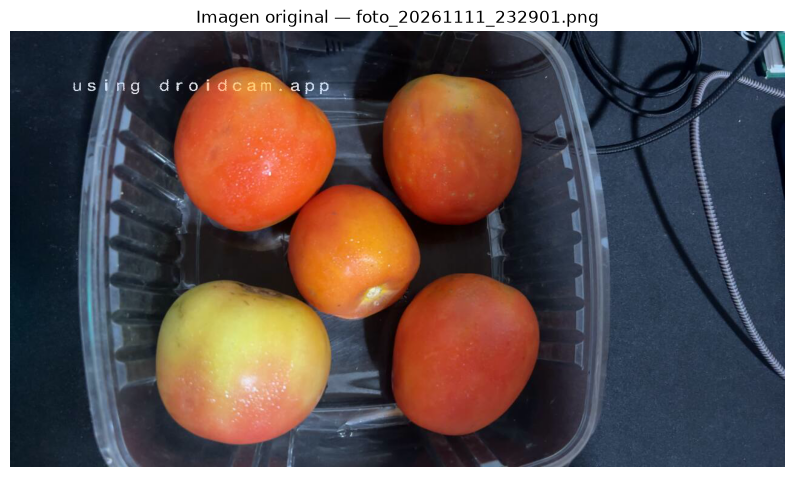

In [2]:
FRUTA = None                    # None = se reconoce sola; o fija: "tomate", "banano", "mango", "manzana"
TOMAR_FOTO = True               # True: abre el celular (ESPACIO = foto, g = guardar, r = repetir, q = usar la última)
NOMBRE_IMAGEN = None            # None = la última foto tomada; o un archivo, p. ej. "mangos.jpg"
ALTURA_CELULAR_CM = cfg.ALTURA_CELULAR_CM   # deducida de un tomate de 5.5 cm (Etapa 7)

# Si hace menos de 2 min se tomó una foto con herramientas/tomar_foto.py (que ya la analizó aquí),
# "Ejecutar todo" no vuelve a abrir la cámara: analiza esa foto.
import time
_recientes = [f for f in cfg.DIR_IMAGENES.glob("foto_*") if time.time() - f.stat().st_mtime < 120]
if TOMAR_FOTO and _recientes:
    print(f"Foto recién tomada ({max(_recientes, key=lambda f: f.stat().st_mtime).name}): no se abre la cámara.")
elif TOMAR_FOTO:
    try:
        nueva = cap.tomar_foto(cfg.ORIGEN_CELULAR, cfg.DIR_IMAGENES)
        print(f"Foto tomada: {nueva.name}" if nueva else "Cancelado: se usa la última foto.")
    except (RuntimeError, TimeoutError) as e:
        print(f"AVISO: no llega imagen del celular ({e}). Se usa la última foto.")

imagenes = cfg.listar_imagenes(cfg.DIR_IMAGENES)
if not imagenes:
    raise FileNotFoundError(
        f"No hay fotografías en {cfg.DIR_IMAGENES}. Copie allí una foto con frutos "
        "en distintas etapas de madurez y vuelva a ejecutar esta celda.")
fotos_tomadas = sorted(cfg.DIR_IMAGENES.glob("foto_*"), key=lambda p: p.stat().st_mtime)
if NOMBRE_IMAGEN:
    RUTA_IMAGEN = cfg.DIR_IMAGENES / NOMBRE_IMAGEN
else:
    RUTA_IMAGEN = fotos_tomadas[-1] if fotos_tomadas else imagenes[0]
NOMBRE = RUTA_IMAGEN.stem
crono = ev.Cronometro()                  # mide el tiempo real de cada etapa

with crono.etapa("1. carga"):
    img_original = proc.cargar_imagen(RUTA_IMAGEN)

if FRUTA is None:                        # reconocimiento automático de la fruta
    with crono.etapa("1. reconocer fruta"):
        RECONOCIMIENTO = rec.reconocer_fruta(img_original)
    FRUTA = RECONOCIMIENTO.fruta
    display(RECONOCIMIENTO.puntajes.style.format({"puntaje": "{:.0%}"}).hide(axis="index")
            .set_caption(f"Fruta reconocida: {FRUTA.upper()}"))

PERFIL = cfg.cargar_perfil(FRUTA)        # colores, forma y etapas de madurez de la fruta
PARAMS = PERFIL.segmentacion             # parámetros de segmentación (editables)
REGLAS = PERFIL.madurez                  # reglas de madurez (editables)

with crono.etapa("1. redimensionado"):
    img, escala = proc.redimensionar(img_original, PARAMS.lado_max, ampliar=True)

print(f"Perfil de fruta     : {PERFIL.nombre} — {PERFIL.descripcion}")
print(f"Etapas de madurez   : {REGLAS.categorias}")
print(f"Imágenes disponibles: {[p.name for p in imagenes]}")
print(f"Analizando          : {RUTA_IMAGEN.name}")
print(f"Resolución original : {img_original.shape[1]} x {img_original.shape[0]} px")
print(f"Resolución de trabajo: {img.shape[1]} x {img.shape[0]} px (escala = {escala:.4f})")

plt.figure(figsize=(10, 7))
plt.imshow(proc.a_rgb(img))
plt.title(f"Imagen original — {RUTA_IMAGEN.name}")
plt.axis("off")
plt.show()

---
# Etapa 2 — Preprocesamiento digital de imágenes con OpenCV

| Técnica | Función OpenCV | Utilidad en AgroVisión |
|---|---|---|
| **RGB** | `cv2.cvtColor(..., COLOR_BGR2RGB)` | OpenCV guarda BGR; RGB es necesario para mostrar con Matplotlib. Los canales R, G, B mezclan color e iluminación, por eso no se segmenta aquí. |
| **HSV** | `COLOR_BGR2HSV` | Separa **tono (H)** de saturación (S) y brillo (V): el tono del fruto (rojo/naranja/verde) cambia poco con sombras. Base de `cv2.inRange`. |
| **LAB** | `COLOR_BGR2LAB` | **a\*** mide el eje verde (−) ↔ rojo (+): describe directamente la maduración. **L** es la luminosidad, sobre la que se ecualiza. |
| **CLAHE** | `cv2.createCLAHE` sobre L | Ecualiza el contraste por zonas: reduce el efecto de sombras del follaje sin cambiar el color. |
| **Mediana** | `cv2.medianBlur` | Elimina ruido impulsivo y pequeños brillos preservando los bordes del fruto. |
| **Gaussiano** | `cv2.GaussianBlur` | Suaviza ruido de sensor y textura fina antes de umbralizar, para obtener máscaras menos fragmentadas. |

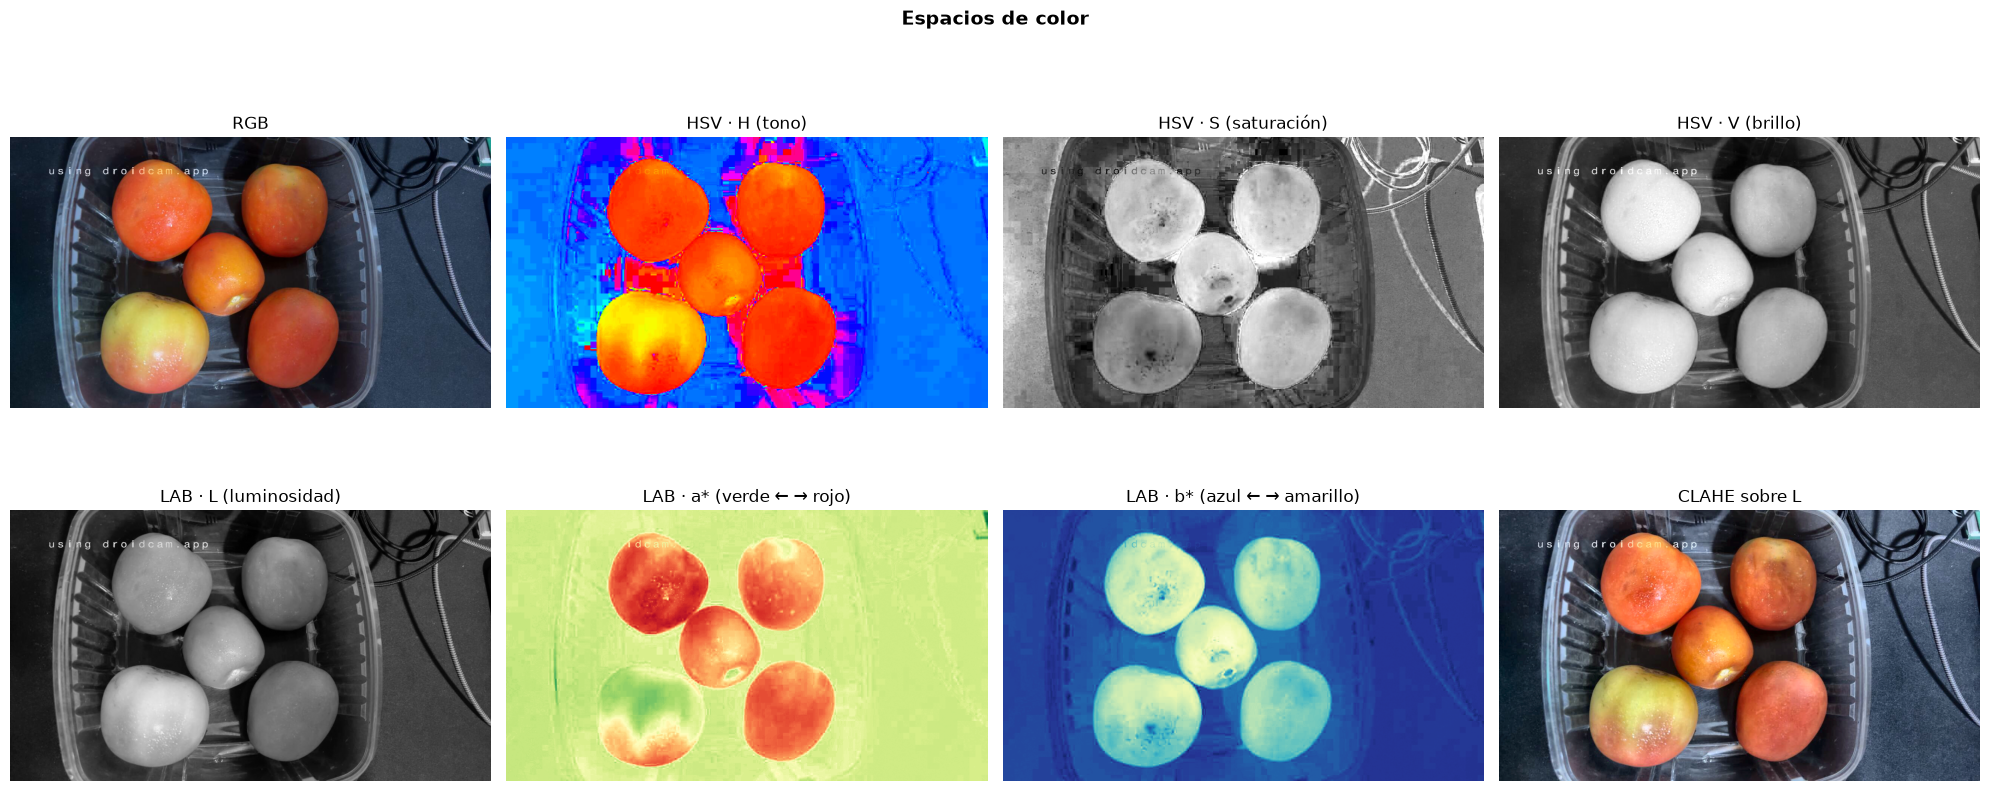

In [3]:
with crono.etapa("2. preprocesamiento"):
    pre = proc.preprocesar(img)

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
H, S, V = cv2.split(hsv)
L, A, B = cv2.split(lab)

fig, ejes = plt.subplots(2, 4, figsize=(20, 9))
paneles = [
    (proc.a_rgb(img), "RGB", None), (H, "HSV · H (tono)", "hsv"),
    (S, "HSV · S (saturación)", "gray"), (V, "HSV · V (brillo)", "gray"),
    (L, "LAB · L (luminosidad)", "gray"),
    (A, "LAB · a* (verde ← → rojo)", "RdYlGn_r"), (B, "LAB · b* (azul ← → amarillo)", "YlGnBu_r"),
    (proc.a_rgb(pre["iluminacion"]), "CLAHE sobre L", None),
]
for ax, (im, t, cm) in zip(ejes.ravel(), paneles):
    ax.imshow(im, cmap=cm)
    ax.set_title(t)
    ax.axis("off")
fig.suptitle("Espacios de color", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.1 Filtros gaussiano y de mediana

Se compara un recorte ampliado para apreciar la diferencia: el gaussiano difumina también los bordes; la mediana conserva mejor el contorno del fruto y elimina puntos aislados.

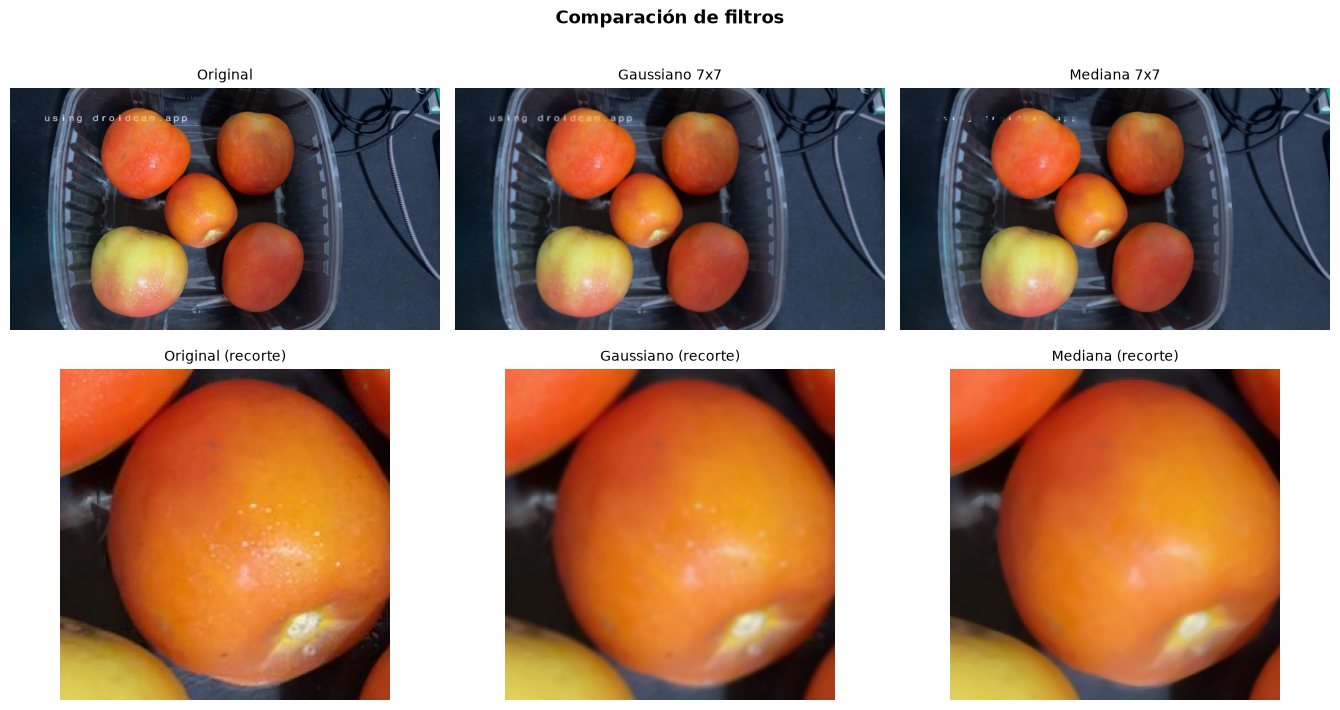

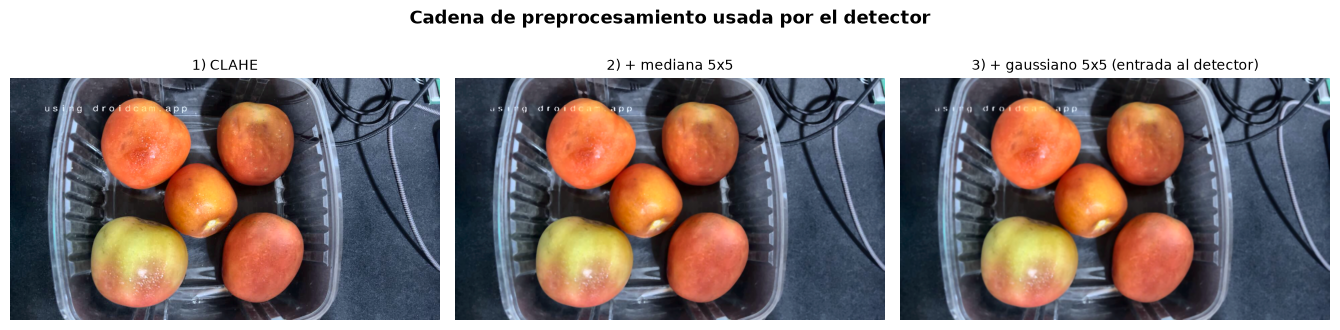

In [4]:
gauss = cv2.GaussianBlur(img, (7, 7), 0)
mediana = cv2.medianBlur(img, 7)

# Recorte centrado en la zona con más píxeles de color distintivo del fruto (o el centro)
mascaras = seg.mascaras_color(hsv, PARAMS)
distintivo = np.zeros(img.shape[:2], np.uint8)
for nombre_c, m in mascaras.items():
    if nombre_c not in PARAMS.colores_follaje:
        distintivo |= m
ys, xs = np.nonzero(distintivo)
cy, cx = (int(np.median(ys)), int(np.median(xs))) if len(ys) else (img.shape[0] // 2, img.shape[1] // 2)
r = min(img.shape[:2]) // 6
y0, x0 = max(cy - r, 0), max(cx - r, 0)
recorte = lambda im: im[y0:y0 + 2 * r, x0:x0 + 2 * r]

vis.mostrar_grilla(
    [img, gauss, mediana, recorte(img), recorte(gauss), recorte(mediana)],
    ["Original", "Gaussiano 7x7", "Mediana 7x7",
     "Original (recorte)", "Gaussiano (recorte)", "Mediana (recorte)"],
    columnas=3, titulo="Comparación de filtros")
plt.show()

vis.mostrar_grilla([pre["iluminacion"], pre["mediana"], pre["suavizada"]],
                   ["1) CLAHE", "2) + mediana 5x5", "3) + gaussiano 5x5 (entrada al detector)"],
                   columnas=3, titulo="Cadena de preprocesamiento usada por el detector")
plt.show()

---
# Etapa 3 — Segmentación, detección y conteo

El color **no basta** para decidir que algo es un fruto (las hojas también son verdes, los tallos pueden ser rojizos). El detector combina:

1. **Color** (`cv2.inRange` en HSV): una máscara por cada clase de color del perfil (en el tomate: rojo —dos intervalos, porque el tono rojo está en ambos extremos 0 y 180—, naranja y verde; en el banano: amarillo, café y verde). Las clases se agrupan en **distintivas** (no aparecen en las hojas) y **de follaje** (`colores_follaje`, normalmente el verde).
2. **Textura** (`cv2.threshold` sobre la desviación estándar local): el fruto es liso, la hoja tiene nervaduras.
3. **Bordes** (`cv2.Canny`): un fruto verde rodeado de hojas verdes solo se separa por su contorno; los bordes se restan de la máscara de follaje.
4. **Morfología** (`cv2.morphologyEx`): *apertura* = erosión+dilatación (quita ruido y estructuras finas como tallos y bordes de hoja); *cierre* = dilatación+erosión (tapa huecos causados por reflejos).
5. **Contornos** (`cv2.findContours`, `RETR_CCOMP`) rellenos, **watershed** para frutos pegados y **unión de pintones** (la parte verde y la madura de un mismo fruto).
6. **Validación geométrica** con `cv2.contourArea`, `cv2.arcLength`, `cv2.boundingRect`, envolvente convexa y `cv2.fitEllipse`. A los candidatos solo verdes se les exige más forma.

| Medida | Fórmula | Tomate típico | Banano típico |
|---|---|---|---|
| Circularidad | 4πA / P² | cercana a 1 | 0.3–0.5 |
| Solidez | A / A_convexa | > 0.9 (sin entrantes) | 0.75–0.9 (curvo) |
| Relación de aspecto | lado mayor / menor del bbox | < 2 | 3–5 |
| Ajuste a elipse | IoU(región, elipse ajustada) | > 0.9 | 0.6–0.8 |

Los umbrales de cada fruta están en la sección `segmentacion` de su perfil.

In [5]:
display(pd.DataFrame([PARAMS.como_dict()]).T.rename(columns={0: "valor"}))

with crono.etapa("3. segmentación + watershed + validación"):
    res = seg.segmentar(img, PARAMS)
E = res.etapas
print(f"Candidatos aceptados: {res.conteo}   |   rechazados (no fruto): {len(res.rechazadas)}")

,valor
lado_max,1280
colores,"{'rojo': [((0, 130, 110), (10, 255, 255)), ((1..."
colores_follaje,"(verde,)"
textura_ventana,9
textura_max_verde,18.0
canny_bajo,20
canny_alto,60
kernel_apertura,5
kernel_cierre,17
kernel_apertura_verde,11


Candidatos aceptados: 5   |   rechazados (no fruto): 4


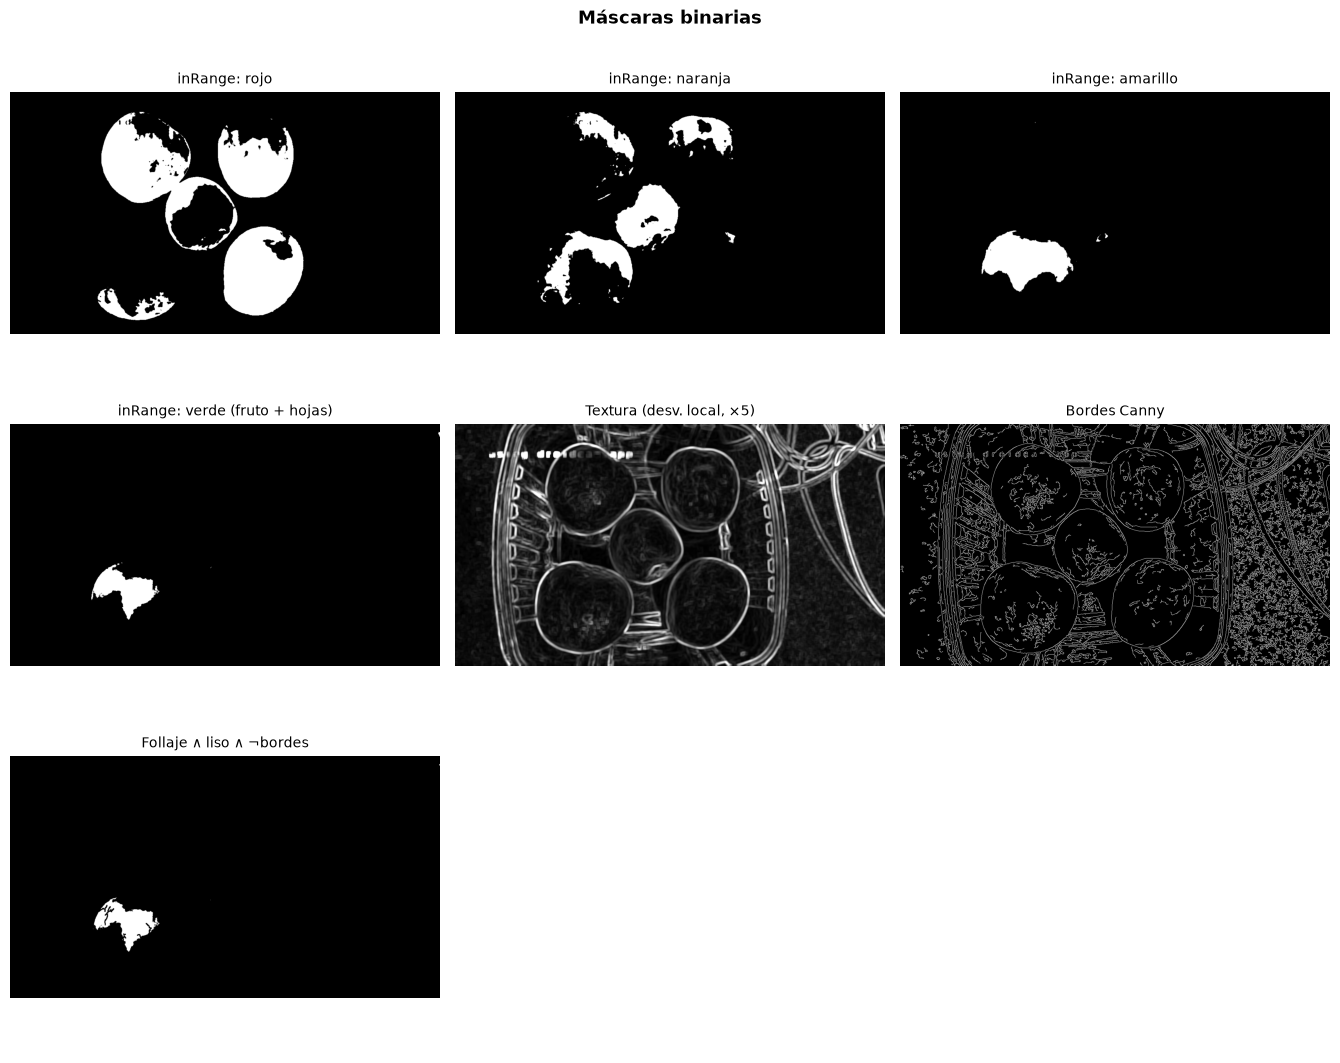

In [6]:
clases = list(PARAMS.colores)
vis.mostrar_grilla(
    [E[f"mascara_{c}"] for c in clases]
    + [np.clip(E["textura_sigma"] * 5, 0, 255).astype(np.uint8), E["bordes"], E["follaje_lisa"]],
    [f"inRange: {c}" + (" (fruto + hojas)" if c in PARAMS.colores_follaje else "") for c in clases]
    + ["Textura (desv. local, ×5)", "Bordes Canny", "Follaje ∧ liso ∧ ¬bordes"],
    columnas=3, titulo="Máscaras binarias")
plt.show()

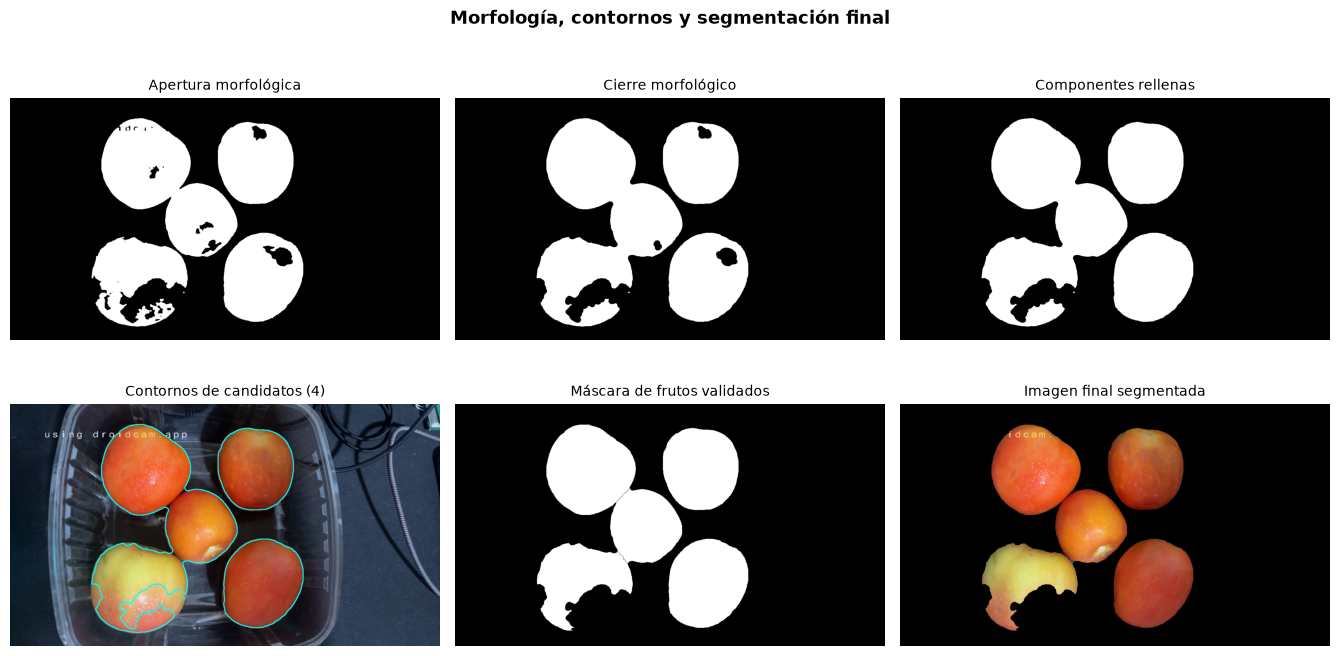

In [7]:
# Contornos de la máscara final y la imagen segmentada
img_contornos = img.copy()
contornos_todos, _ = cv2.findContours(E["mascara_final"], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img_contornos, contornos_todos, -1, (255, 255, 0), 2)
mascara_frutos = np.zeros(img.shape[:2], np.uint8)
for d in res.detecciones:
    mascara_frutos |= d.mascara_completa(img.shape)
img_segmentada = cv2.bitwise_and(img, img, mask=mascara_frutos)

vis.mostrar_grilla(
    [E["apertura"], E["cierre"], E["mascara_final"], img_contornos, mascara_frutos, img_segmentada],
    ["Apertura morfológica", "Cierre morfológico", "Componentes rellenas",
     f"Contornos de candidatos ({len(contornos_todos)})", "Máscara de frutos validados",
     "Imagen final segmentada"],
    columnas=3, titulo="Morfología, contornos y segmentación final")
plt.show()

### 3.1 Comparativa de técnicas (resumen visual)

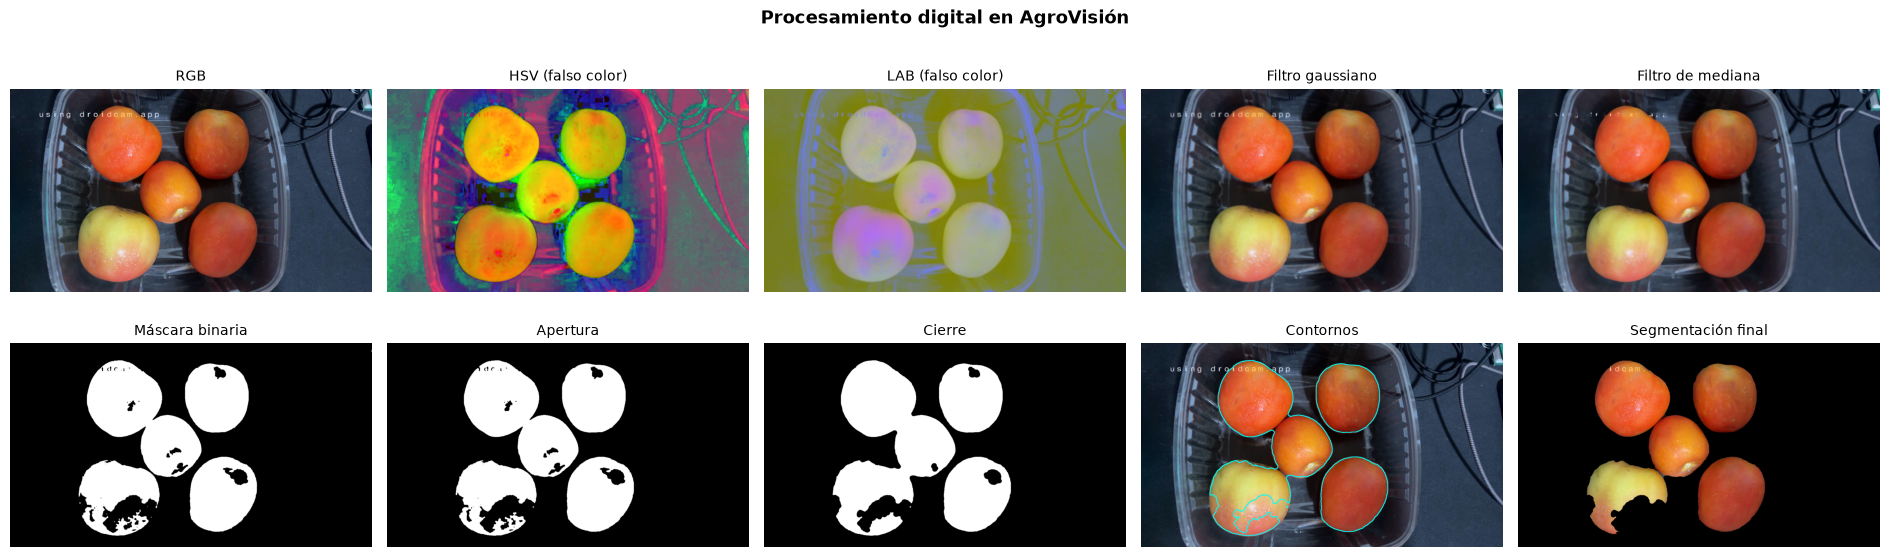

In [8]:
vis.mostrar_grilla(
    [img, E["hsv"], E["lab"], cv2.GaussianBlur(img, (7, 7), 0), cv2.medianBlur(img, 7),
     E["mascara_distintiva"] | E["follaje_lisa"],
     E["apertura"], E["cierre"], img_contornos, img_segmentada],
    ["RGB", "HSV (falso color)", "LAB (falso color)", "Filtro gaussiano", "Filtro de mediana",
     "Máscara binaria", "Apertura", "Cierre", "Contornos", "Segmentación final"],
    columnas=5, tam_celda=3.8, titulo="Procesamiento digital en AgroVisión")
plt.show()

### 3.2 Watershed para frutos unidos

Cuando dos frutos se tocan, la máscara forma una sola región con un "cuello" (solidez baja). La **transformada de distancia** (`cv2.distanceTransform`) tiene un máximo en el centro de cada fruto; esos máximos son las semillas de `cv2.watershed`, que traza la frontera entre ellos. Solo se aplica a regiones con solidez < `solidez_para_watershed`. En frutos alargados y curvos (banano) ese umbral es bajo, porque un solo banano ya tiene solidez < 0.9 y se partiría en trozos.

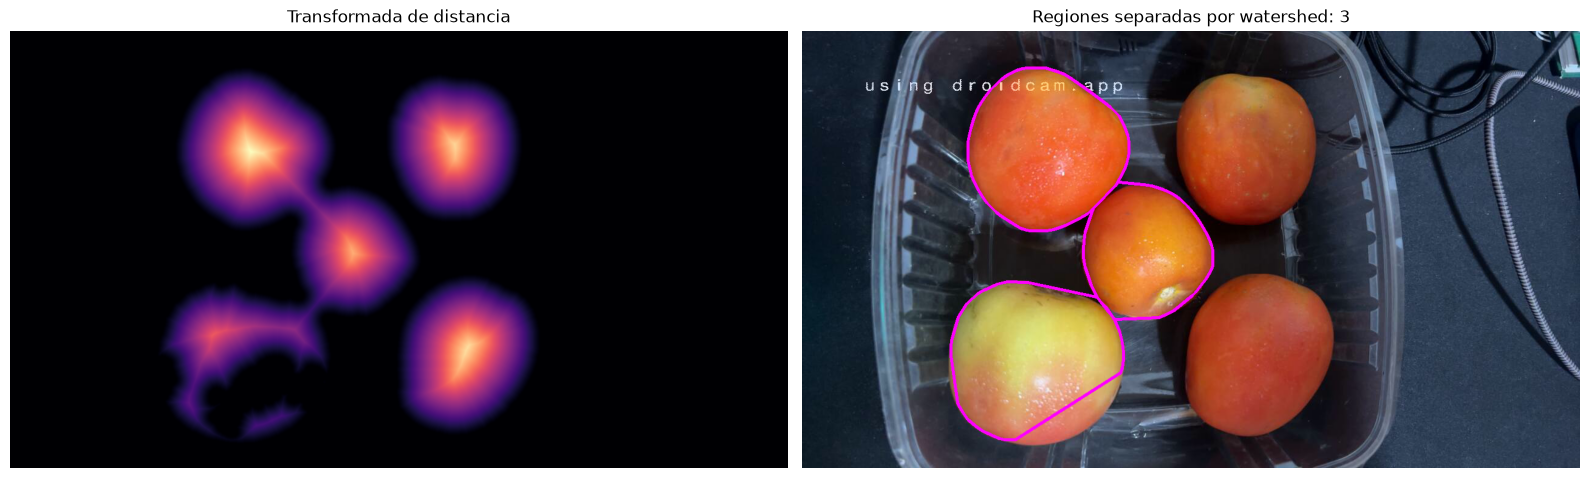

In [9]:
dist = cv2.distanceTransform(E["mascara_final"], cv2.DIST_L2, 5)
img_ws = img.copy()
n_ws = 0
for d in res.detecciones:
    if d.por_watershed:
        n_ws += 1
        cv2.drawContours(img_ws, [d.contorno], -1, (255, 0, 255), 3)
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
ejes[0].imshow(dist, cmap="magma"); ejes[0].set_title("Transformada de distancia"); ejes[0].axis("off")
ejes[1].imshow(proc.a_rgb(img_ws)); ejes[1].set_title(f"Regiones separadas por watershed: {n_ws}")
ejes[1].axis("off")
plt.tight_layout(); plt.show()

### 3.3 Detecciones, identificadores y candidatos rechazados

Cada detección válida recibe un identificador único (orden de lectura: de arriba a abajo, de izquierda a derecha). En gris se muestran los candidatos **rechazados** y abajo el motivo: así se comprueba que no se cuenta cada contorno como fruto.

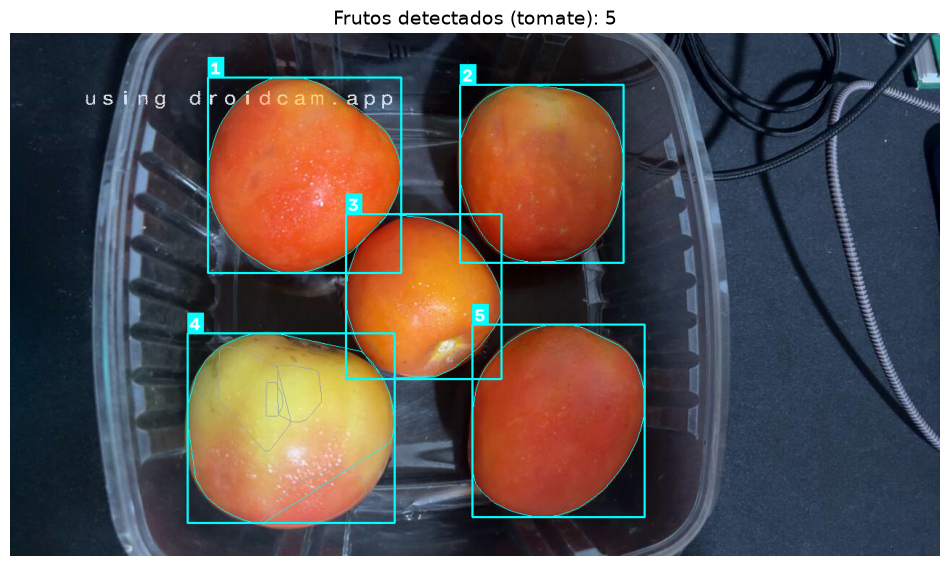

,candidatos rechazados
pequeña frente a los demás,3
área pequeña,1


In [10]:
img_det = vis.dibujar_detecciones(img, res.detecciones, rechazadas=res.rechazadas)
plt.figure(figsize=(12, 8))
plt.imshow(proc.a_rgb(img_det))
plt.title(f"Frutos detectados ({PERFIL.nombre}): {res.conteo}", fontsize=14)
plt.axis("off")
plt.show()

motivos = pd.Series([r.motivo for r in res.rechazadas], dtype="object").value_counts()
display(motivos.rename("candidatos rechazados").to_frame())

---
# Etapa 4 — Extracción de características y clasificación de madurez

Para cada fruto se calculan descriptores **dentro de su máscara** (no del rectángulo, para no mezclar hojas del fondo):

* Geométricos: área, perímetro, circularidad, solidez, ajuste a elipse, relación de aspecto, ancho/alto del bounding box, centroide (momentos `cv2.moments`), diámetro equivalente √(4A/π).
* Color: media y desviación de H, S, V; a\* y b\* de LAB; histograma de tono (18 bins); **% de superficie de cada clase de color del perfil** (píxeles con S o V muy bajos —reflejos, sombras— se excluyen). Cada píxel cuenta para la primera clase, en el orden del perfil, cuyo intervalo HSV lo contiene.

### Reglas de madurez (sección `madurez` del perfil)
Cada etapa tiene porcentajes **mínimos** y **máximos** por clase de color. Se recorren en orden y gana la primera que se cumple; si ninguna se cumple, se asigna la etapa `por_defecto`. Por ejemplo:
* **Tomate:** Verde si verde ≥ 60 % y rojo ≤ 10 %; Maduro si rojo ≥ 60 %; Pintón en otro caso.
* **Banano:** Verde si verde ≥ 70 %; Maduro si amarillo ≥ 70 % y café ≤ 15 %; Sobremaduro si café ≥ 15 %; Pintón en otro caso.

La tabla de abajo muestra las reglas del perfil activo.

In [11]:
with crono.etapa("4. características"):
    df = car.extraer_caracteristicas(res, REGLAS)
with crono.etapa("4. clasificación por reglas"):
    df = clas.aplicar_reglas(df, REGLAS)

display(pd.DataFrame([{"etapa": e.nombre, "mínimos": e.minimos, "máximos": e.maximos,
                       "por defecto": e.nombre == REGLAS.por_defecto} for e in REGLAS.etapas]))
columnas_vista = ["id", "categoria", "area_px", "perimetro_px", "circularidad", "solidez",
                  "ajuste_elipse", "relacion_aspecto", "ancho_bbox_px", "alto_bbox_px",
                  "centroide_x", "centroide_y", "diametro_equiv_px", "H_media", "S_media",
                  "V_media", "a_media", *REGLAS.columnas_pct]
display(df[columnas_vista] if len(df) else df)

,etapa,mínimos,máximos,por defecto
0,Verde,{'verde': 0.6},{'rojo': 0.1},False
1,Pintón,{},{},True
2,Maduro,{'rojo': 0.25},{'verde': 0.15},False


,id,categoria,area_px,perimetro_px,circularidad,solidez,ajuste_elipse,relacion_aspecto,ancho_bbox_px,alto_bbox_px,centroide_x,centroide_y,diametro_equiv_px,H_media,S_media,V_media,a_media,pct_rojo,pct_naranja,pct_verde
0,1,Maduro,53450.5,826.051,0.984,1.0,0.942,0.989,266,269,399.121,195.090,260.874,9.146,178.255,242.384,41.864,0.803,0.197,0.000
1,2,Maduro,44760.5,754.929,0.987,1.0,0.960,0.918,225,245,730.370,190.779,238.728,9.311,179.476,195.273,34.291,0.724,0.276,0.000
2,3,Maduro,36857.0,692.078,0.967,1.0,0.935,0.943,214,227,563.434,364.030,216.628,12.694,196.542,215.736,32.278,0.329,0.669,0.002
3,4,Pintón,54600.0,859.567,0.929,1.0,0.848,1.092,285,261,374.836,533.729,263.664,22.669,136.388,206.685,0.070,0.106,0.376,0.518
4,5,Maduro,49835.5,800.818,0.977,1.0,0.960,0.894,237,265,749.334,532.274,251.898,5.978,164.985,210.910,40.225,0.991,0.009,0.000


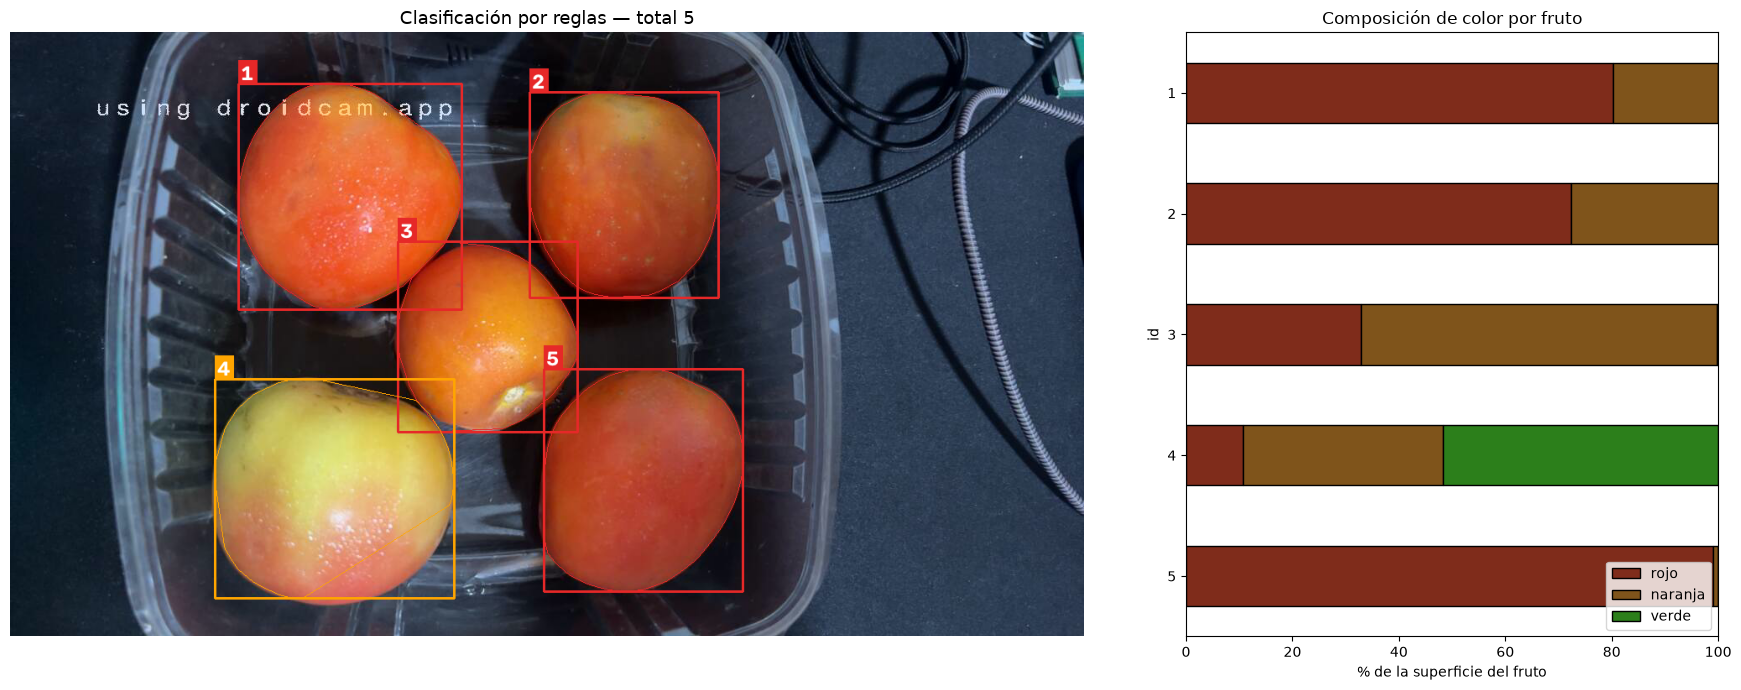

Conteo por categoría:
  Verde      : 0
  Pintón     : 1
  Maduro     : 4
  TOTAL      : 5


In [12]:
img_clasif = vis.dibujar_detecciones(img, res.detecciones, df, REGLAS)
conteos = df["categoria"].value_counts().reindex(REGLAS.categorias, fill_value=0) if len(df) else \
    pd.Series(0, index=REGLAS.categorias)

fig, ejes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2.2, 1]})
ejes[0].imshow(proc.a_rgb(img_clasif)); ejes[0].axis("off")
ejes[0].set_title(f"Clasificación por reglas — total {len(df)}", fontsize=13)
if len(df):
    pct = df.set_index("id")[REGLAS.columnas_pct] * 100
    pct.plot.barh(stacked=True, ax=ejes[1], edgecolor="black",
                  color=[vis.color_clase_mpl(r) for r in REGLAS.colores.values()])
    ejes[1].invert_yaxis()
    ejes[1].legend(list(REGLAS.colores), loc="lower right")
ejes[1].set_xlabel("% de la superficie del fruto"); ejes[1].set_title("Composición de color por fruto")
plt.tight_layout(); plt.show()

print("Conteo por categoría:")
for c in REGLAS.categorias:
    print(f"  {c:11s}: {conteos[c]}")
print(f"  {'TOTAL':11s}: {len(df)}")

In [13]:
# Guardar resultados de la imagen analizada
ruta_csv = cfg.DIR_RES_ESTADISTICAS / f"{NOMBRE}_caracteristicas.csv"
df.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
proc.guardar_imagen(cfg.DIR_RES_DETECCIONES / f"{NOMBRE}_detecciones.png", img_clasif)
proc.guardar_imagen(cfg.DIR_RES_SEGMENTACIONES / f"{NOMBRE}_mascara.png", mascara_frutos)
proc.guardar_imagen(cfg.DIR_RES_SEGMENTACIONES / f"{NOMBRE}_segmentada.png", img_segmentada)
print("Guardado en:", ruta_csv.relative_to(cfg.RAIZ), "y carpetas resultados/detecciones, segmentaciones")

Guardado en: resultados\estadisticas\foto_20261111_232901_caracteristicas.csv y carpetas resultados/detecciones, segmentaciones


### 4.1 Clasificador ligero (SVM, k-NN, árbol de decisión)

Para entrenar se necesitan **etiquetas reales**. Procedimiento:

1. La celda siguiente agrega las detecciones de esta imagen a `data/etiquetas_madurez_<fruta>.csv` (un archivo por fruta, porque cada una tiene sus propias clases de color) con la columna `categoria_real` **vacía**.
2. Abra el CSV (Excel o VS Code) y, mirando la imagen numerada de arriba, escriba una de las etapas del perfil (en el tomate: `Verde`, `Pintón` o `Maduro`) en `categoria_real` (deje vacíos los que no sean frutos o sean dudosos).
3. Repita con varias fotos (se recomiendan ≥ 5 ejemplos por clase; más es mejor).
4. Vuelva a ejecutar: se comparan reglas vs. SVM, k-NN y árbol con **validación cruzada estratificada** (cada predicción se hace con un modelo que no vio ese ejemplo).

In [14]:
EXPORTAR_PARA_ETIQUETAR = True
if EXPORTAR_PARA_ETIQUETAR and len(df):
    ruta = clas.exportar_para_etiquetar(df, RUTA_IMAGEN.name, REGLAS, PERFIL.archivo_etiquetas)
    print("Archivo de etiquetado:", ruta.relative_to(cfg.RAIZ))

df_etiq = clas.cargar_etiquetas(PERFIL.archivo_etiquetas, REGLAS)
tabla_cmp, preds_cv = clas.comparar_clasificadores(df_etiq, REGLAS, min_por_clase=5)
if tabla_cmp is None:
    print("PENDIENTE —", preds_cv)
else:
    display(tabla_cmp)
    fig, ejes = plt.subplots(1, len(preds_cv), figsize=(4.5 * len(preds_cv), 4))
    for ax, (nombre, pred) in zip(np.atleast_1d(ejes), preds_cv.items()):
        r_cls = ev.evaluar_clasificacion(df_etiq["categoria_real"], pred, REGLAS.categorias)
        ax.imshow(r_cls["matriz"].values, cmap="Blues")
        for (i, j), v in np.ndenumerate(r_cls["matriz"].values):
            ax.text(j, i, v, ha="center", va="center", fontsize=12)
        ax.set_xticks(range(len(r_cls["matriz"].columns)), r_cls["matriz"].columns, rotation=30)
        ax.set_yticks(range(len(r_cls["matriz"].index)), r_cls["matriz"].index)
        ax.set_title(f"{nombre}\nexactitud {r_cls['exactitud']:.2f}")
    plt.tight_layout(); plt.show()
    mejor = tabla_cmp[tabla_cmp["metodo"] != "Reglas de color"].sort_values("f1_macro").iloc[-1]["metodo"]
    print("Modelo guardado:", clas.entrenar_y_guardar(df_etiq, mejor, REGLAS, PERFIL.archivo_modelo).relative_to(cfg.RAIZ), f"({mejor})")

'foto_20261111_232901.png' ya está en etiquetas_madurez_tomate.csv; no se modifica.
Archivo de etiquetado: data\etiquetas_madurez_tomate.csv
PENDIENTE — No hay etiquetas manuales todavía.


---
# Etapa 5 — Preparación de imágenes estereoscópicas (Modo 2: un celular)

> ⚠️ **Modo experimental.** Dos fotos tomadas con el mismo celular en instantes distintos **no equivalen** a dos cámaras capturando simultáneamente. Si algo en la escena se mueve entre fotos (viento, hojas, luz), la correspondencia falla y la profundidad es errónea. Úselo solo con escenas **estáticas**.

### Cómo tomar las fotografías
1. Apoye el celular en una **referencia estable**: una regla o listón fijado a la mesa, o un riel. El celular debe deslizarse sin girar.
2. Bloquee **enfoque y exposición** (mantenga pulsado sobre la pantalla en la app de cámara), desactive zoom, HDR, modo retrato y "IA".
3. Misma **orientación** en ambas fotos (las dos horizontales o las dos verticales).
4. Foto **izquierda** → deslice el celular **horizontalmente hacia la derecha** una distancia conocida (p. ej. 6-10 cm; anótela: es la *línea base*) → foto **derecha**. Sin cambiar altura ni inclinación.
5. Distancia a los frutos: 40-150 cm. Con la línea base B, la distancia focal f y la disparidad d: **Z = f·B/d**; más línea base ⇒ más precisión a distancia, pero menos superposición.
6. Guarde las fotos con el mismo nombre en `data/estereo/izquierda/` y `data/estereo/derecha/` (se emparejan por orden alfabético).

Para profundidad **métrica** en este modo (sin tablero) se necesita además:
* la **focal** del celular (Etapa 6: ficha técnica o EXIF), y
* la **línea base medida** con la regla → pose con la matriz esencial (`cv2.findEssentialMat` + `cv2.recoverPose`) escalada por B.

In [15]:
PAR_INDICE = 0
PREFIJO_M3 = "m3_"   # los pares capturados en el Modo 3 llevan este prefijo

pares_m2 = [(i, d) for i, d in zip(
    [p for p in cfg.listar_imagenes(cfg.DIR_EST_IZQ) if not p.name.startswith(PREFIJO_M3)],
    [p for p in cfg.listar_imagenes(cfg.DIR_EST_DER) if not p.name.startswith(PREFIJO_M3)])]
hay_par_m2 = len(pares_m2) > PAR_INDICE

def tam_trabajo(img_ref, lado_max=1280):
    h, w = img_ref.shape[:2]
    s = min(1.0, lado_max / max(h, w))
    return (int(round(w * s)), int(round(h * s)))

if hay_par_m2:
    ruta_i, ruta_d = pares_m2[PAR_INDICE]
    izq_raw, der_raw = proc.cargar_imagen(ruta_i), proc.cargar_imagen(ruta_d)
    verif = est.verificar_par(izq_raw, der_raw)
    print(f"Par: {ruta_i.name} / {ruta_d.name}")
    print("  Izquierda:", verif["izquierda"], "| Derecha:", verif["derecha"])
    for a in verif["avisos"]:
        print("  AVISO:", a)
    TAM_M2 = tam_trabajo(izq_raw)
    izq_m2, der_m2 = est.armonizar(izq_raw, TAM_M2), est.armonizar(der_raw, TAM_M2)
    print(f"  Tamaño de trabajo: {TAM_M2[0]}x{TAM_M2[1]}")
    vis.mostrar_grilla([izq_m2, der_m2], ["Vista izquierda", "Vista derecha"], columnas=2, tam_celda=7)
    plt.show()
else:
    TAM_M2 = None
    print("PENDIENTE — No hay pares en data/estereo/izquierda y data/estereo/derecha.")

PENDIENTE — No hay pares en data/estereo/izquierda y data/estereo/derecha.


---
# Etapa 6 — Calibración sin tablero, rectificación y disparidad

### 6.1 Cómo se calibra sin tablero
La calibración clásica (`cv2.calibrateCamera` / `cv2.stereoCalibrate`) necesita fotografiar un patrón impreso de medidas conocidas. En este proyecto **no se usa tablero**: cada parámetro se obtiene de datos que ya se tienen.

| Parámetro | Con tablero (no se usa) | Sin tablero (este proyecto) |
|---|---|---|
| Focal f (px) | `calibrateCamera` | ficha técnica: focal equivalente a 35 mm (celular) o campo de visión FOV (webcam): **f = (ancho/2) / tan(FOV/2)** |
| Centro óptico (cx, cy) | `calibrateCamera` | centro de la imagen |
| Distorsión | `calibrateCamera` | se supone nula (celulares y webcams ya la corrigen) |
| Rotación R entre vistas | `stereoCalibrate` | **matriz esencial** con puntos SIFT de la propia escena (`findEssentialMat` + `recoverPose`) |
| Escala de T | tamaño del cuadro | **línea base medida con regla** |

**Qué se pierde:** no hay error RMS de reproyección para verificar la calibración, y un error de x % en la focal produce ~x % de error en la **profundidad Z**.
**Qué se conserva:** el tamaño físico es tamaño_px · Z / f = tamaño_px · B / d, así que el error de la focal **se cancela en primera aproximación** en las dimensiones de los frutos; lo que más pesa es medir bien la línea base B.
La verificación se hace con el **error vertical tras rectificar** (puntos homólogos en la misma fila: < 1-2 px).

### 6.2 Intrínsecos del celular (Modo 2)

K aproximada a partir de la *focal equivalente a 35 mm* del lente principal (`F35_CELULAR`, de la ficha técnica del celular, o del EXIF de la foto si se pasó como archivo original; WhatsApp borra el EXIF): f_px = f35 · diagonal_px / 43.27, centro en el medio de la imagen, sin distorsión.

In [16]:
# Focal equivalente a 35 mm del lente principal. Si es None se lee del EXIF de la
# foto izquierda (solo si se pasó como original, no por WhatsApp).
F35_CELULAR = cfg.F35_CELULAR     # iPhone 15, cámara principal (1x): 26 mm equivalentes
cal_cel = None
f35 = F35_CELULAR or (est.f35_desde_exif(ruta_i) if hay_par_m2 else None)

if f35 and TAM_M2:
    cal_cel = est.calibracion_aproximada(TAM_M2, f35)
    print(cal_cel.resumen())
elif not f35:
    print("PENDIENTE — Indique F35_CELULAR (ficha técnica) o use una foto izquierda con EXIF.")
else:
    print("PENDIENTE — Se requiere un par estéreo (Etapa 5).")

PENDIENTE — Se requiere un par estéreo (Etapa 5).


### 6.3 Geometría entre vistas, rectificación y disparidad (Modo 2)

* **Con calibración:** se estima la pose relativa (R, T) y se rectifica con `cv2.stereoRectify` + `cv2.initUndistortRectifyMap` + `cv2.remap`, que además **corrige la distorsión**.
* **Sin calibración:** `cv2.findFundamentalMat` + `cv2.stereoRectifyUncalibrated`. Sirve para ver si el par es aprovechable, pero **la disparidad es relativa y no se convierte en profundidad**.

**Rectificar** = transformar ambas imágenes para que cada punto tenga su homólogo **en la misma fila**: la búsqueda de correspondencias se vuelve 1D. Se verifica midiendo |y_izq − y_der| en puntos SIFT emparejados.

**StereoSGBM** (Semi-Global Block Matching) compara bloques a lo largo de la fila y agrega costos en varias direcciones con penalizaciones P1/P2 a cambios de disparidad, obteniendo mapas más continuos que el block matching simple.

In [17]:
LINEA_BASE_M2_MM = 85.6        # desplazamiento = largo de una tarjeta bancaria (85.6 mm)
# Corrimiento esperado = f·B/Z: con B = 85.6 mm y frutos a 45-70 cm, entre ~120 y ~185 px.
SGBM = cfg.ParametrosSGBM(num_disparidades=192)

cal_est_m2, rect_m2, disp_m2 = None, None, None
if hay_par_m2 and cal_cel is not None:
    try:
        if LINEA_BASE_M2_MM:
            cal_est_m2, info = est.pose_por_esencial(izq_m2, der_m2, cal_cel, LINEA_BASE_M2_MM)
            print("Correspondencias:", info)
            giro = np.degrees(np.linalg.norm(cv2.Rodrigues(cal_est_m2.R)[0]))
            if giro > 5:
                print(f"AVISO: el celular giró {giro:.1f}° entre las dos fotos (debe deslizarse sin girar). "
                      "La línea base medida deja de valer y la profundidad no es confiable: repita el par.")
        else:
            print("PENDIENTE — Indique LINEA_BASE_M2_MM.")
    except RuntimeError as e:
        print("No se pudo estimar la pose:", e)

if cal_est_m2 is not None:
    print(cal_est_m2.resumen())
    rect_m2 = est.calcular_rectificacion(cal_est_m2)
    ri_m2, rd_m2 = est.rectificar_par(izq_m2, der_m2, rect_m2)
    etiqueta_m2 = "calibrada (métrica)"
elif hay_par_m2:
    ri_m2, rd_m2, info_nc = est.rectificacion_no_calibrada(izq_m2, der_m2)
    print(f"Rectificación NO calibrada — correspondencias {info_nc['correspondencias']}, "
          f"inliers {info_nc['inliers']}")
    etiqueta_m2 = "NO calibrada (disparidad relativa, sin profundidad)"

if hay_par_m2:
    err = est.error_epipolar_vertical(ri_m2, rd_m2)
    print(f"Error vertical tras rectificar: mediana {err['mediana_px']:.2f} px, "
          f"p90 {err['p90_px']:.2f} px (n={err['n']})")
    disp_m2 = est.calcular_disparidad(ri_m2, rd_m2, SGBM)
    print(f"Píxeles con disparidad válida: {np.isfinite(disp_m2).mean() * 100:.1f} %")
    vis.mostrar_grilla([vis.lineas_epipolares(ri_m2, rd_m2), vis.mapa_disparidad_color(disp_m2)],
                       [f"Par rectificado — {etiqueta_m2}", "Disparidad StereoSGBM (cálido = cerca)"],
                       columnas=2, tam_celda=8)
    plt.show()
    proc.guardar_imagen(cfg.DIR_RES_DISPARIDAD / f"m2_{ruta_i.stem}_disparidad.png",
                        vis.mapa_disparidad_color(disp_m2))
else:
    print("PENDIENTE — Se requiere un par estéreo (Etapa 5).")

PENDIENTE — Se requiere un par estéreo (Etapa 5).


### 6.4 Modo 3 — Cámara del PC (izquierda) + celular por DroidCam (derecha)

**Conexión con DroidCam**
1. Instale **DroidCam** en el celular (Android o iPhone) y el **cliente DroidCam** en Windows; conecte por **USB** (menos retraso) o por Wi-Fi (misma red).
2. Windows ve el celular como otra webcam: `ORIGEN_DER = 1` (o 2). Para encontrar el índice: `python herramientas/probar_camara.py --listar`, y para medir el retraso: `python herramientas/probar_camara.py 0 1`.
3. Sin el cliente de Windows también sirve la URL del celular: `ORIGEN_DER = "http://IP_DEL_CELULAR:4747/video"` (más retraso).
4. En la app **bloquee el enfoque** y no use zoom: si cambian, cambia la focal.

**Montaje físico**
* Fije **rígidamente** el celular junto a la cámara del PC (soporte pegado a la tapa del portátil, o ambos sobre una tabla), a la misma altura, mirando en la misma dirección y con **campos de visión superpuestos** en la zona de los frutos.
* Mida con una regla la separación horizontal entre los dos lentes (**línea base**, 8-20 cm) → `LINEA_BASE_MEDIDA_M3_MM`. Es la única medida física que necesita el método y fija la escala de todas las distancias.
* Las cámaras son distintas (resolución, focal): las imágenes se armonizan a `TAM_M3` (recorte central + reescalado) con la misma transformación.

**Sincronización:** no hay disparo simultáneo por hardware. Cada cámara se lee en un hilo que guarda solo el último fotograma y se mide el desfase entre llegadas; las capturas con desfase > 80 ms se rechazan. Aun así, **usar solo escenas estáticas**.

**Captura:** ventana de OpenCV con `c` = capturar, `s` = intercambiar izquierda/derecha, `q` = salir. Se capturan directamente pares de la **escena** (no hay pares de calibración). La escena debe tener **textura** (no un fondo liso) para que SIFT encuentre correspondencias. Si usa `s`, ponga `INTERCAMBIAR` acorde: define qué focal corresponde a cada lado.

In [18]:
ORIGEN_IZQ = 0                     # cámara integrada del PC
ORIGEN_DER = 1                     # DroidCam (cliente de Windows) o "http://IP_DEL_CELULAR:4747/video"
INTERCAMBIAR = False               # True: celular = izquierda, PC = derecha
TAM_M3 = (1280, 720)               # tamaño común de trabajo (16:9)
LINEA_BASE_MEDIDA_M3_MM = None     # <-- separación entre lentes medida con regla (mm)

CAPTURAR_ESCENA_M3 = False         # True para abrir las cámaras y capturar pares de la escena

if CAPTURAR_ESCENA_M3:
    o_i, o_d = (ORIGEN_DER, ORIGEN_IZQ) if INTERCAMBIAR else (ORIGEN_IZQ, ORIGEN_DER)
    par = cap.ParEstereo(o_i, o_d, nombres=("izquierda", "derecha"), resolucion=(1280, 720))
    try:
        n = cap.capturar_interactivo(par, cfg.DIR_EST_IZQ, cfg.DIR_EST_DER, prefijo=PREFIJO_M3 + "escena")
        print(f"Capturados {n} pares de la escena")
    finally:
        par.cerrar()
else:
    print("Captura desactivada (ponga CAPTURAR_ESCENA_M3 = True con DroidCam conectado).")

Captura desactivada (ponga CAPTURAR_ESCENA_M3 = True con DroidCam conectado).


#### Geometría PC + celular sin tablero

1. **Intrínsecos** de cada cámara por su campo de visión: la webcam del PC con `FOV_PC_GRADOS` (ficha técnica del portátil o de la webcam; si no aparece, ~70° horizontal es lo típico) y el celular con su focal equivalente `F35_CELULAR` convertida a FOV horizontal (el video 16:9 recorta arriba y abajo del sensor 4:3, así que conserva el ángulo horizontal).
2. **Pose relativa:** puntos SIFT emparejados entre las dos cámaras en el par de escena; cada punto se normaliza con la K de **su** cámara y la matriz esencial da R y la dirección de T.
3. **Escala:** |T| = línea base medida con la regla.
4. **Verificación:** rotación relativa pequeña (cámaras casi paralelas) y error vertical tras rectificar < 1-2 px.

In [19]:
FOV_PC_GRADOS = 70.0           # <-- campo de visión de la webcam del PC (ficha técnica)
EJE_FOV_PC = "horizontal"      # "horizontal" o "diagonal", según lo indique la ficha
F35_CELULAR_M3 = F35_CELULAR   # focal equivalente del lente que usa DroidCam (normalmente el principal)

cal_pc = est.calibracion_por_fov(TAM_M3, FOV_PC_GRADOS, EJE_FOV_PC)
cal_droidcam = est.calibracion_por_fov(TAM_M3, est.fov_horizontal_desde_f35(F35_CELULAR_M3))
cal_izq_m3, cal_der_m3 = (cal_droidcam, cal_pc) if INTERCAMBIAR else (cal_pc, cal_droidcam)
print("Izquierda:", cal_izq_m3.resumen())
print("Derecha:  ", cal_der_m3.resumen())

pares_m3 = list(zip([p for p in cfg.listar_imagenes(cfg.DIR_EST_IZQ) if p.name.startswith(PREFIJO_M3)],
                    [p for p in cfg.listar_imagenes(cfg.DIR_EST_DER) if p.name.startswith(PREFIJO_M3)]))
cal_est_m3 = None
if not pares_m3:
    print("PENDIENTE — No hay pares de escena del Modo 3 (capture con CAPTURAR_ESCENA_M3 = True).")
elif not LINEA_BASE_MEDIDA_M3_MM:
    print("PENDIENTE — Indique LINEA_BASE_MEDIDA_M3_MM (separación entre lentes medida con regla).")
else:
    ri_path, rd_path = pares_m3[-1]
    izq_m3 = est.armonizar(proc.cargar_imagen(ri_path), TAM_M3)
    der_m3 = est.armonizar(proc.cargar_imagen(rd_path), TAM_M3)
    try:
        cal_est_m3, info = est.pose_por_esencial(izq_m3, der_m3, cal_izq_m3, LINEA_BASE_MEDIDA_M3_MM,
                                                 cal_der=cal_der_m3)
        print(f"Par: {ri_path.name} / {rd_path.name} — {info}")
        print(cal_est_m3.resumen())
        giro = np.degrees(np.linalg.norm(cv2.Rodrigues(cal_est_m3.R)[0]))
        if giro > 10:
            print(f"AVISO: rotación relativa de {giro:.1f}°: alinee mejor las cámaras (ejes casi paralelos).")
        if cal_est_m3.T[0, 0] > 0:
            print("AVISO: T_x > 0 indica que izquierda y derecha están invertidas. Use INTERCAMBIAR.")
        err = est.error_epipolar_vertical(*est.rectificar_par(izq_m3, der_m3, est.calcular_rectificacion(cal_est_m3)))
        print(f"Verificación — error vertical tras rectificar: mediana {err['mediana_px']:.2f} px, "
              f"p90 {err['p90_px']:.2f} px (n={err['n']})")
    except RuntimeError as e:
        print("No se pudo estimar la pose:", e)

Izquierda: Imagen 1280x720 | calibración aproximada (FOV horizontal = 70°)
  fx=914.0 fy=914.0 cx=639.5 cy=359.5
  distorsión = [0. 0. 0. 0. 0.]
Derecha:   Imagen 1280x720 | calibración aproximada (FOV horizontal = 67.2991°)
  fx=961.5 fy=961.5 cx=639.5 cy=359.5
  distorsión = [0. 0. 0. 0. 0.]
PENDIENTE — No hay pares de escena del Modo 3 (capture con CAPTURAR_ESCENA_M3 = True).


---
# Etapa 7 — Estimación de profundidad y dimensiones

Se distinguen tres magnitudes:

| Magnitud | Unidad | Requisito |
|---|---|---|
| **Tamaño aparente** | píxeles | Solo la imagen (Etapas 3-4) |
| **Profundidad Z** | mm | Calibración estéreo válida + disparidad: `cv2.reprojectImageTo3D(disp, Q)`, equivalente a **Z = f·B/d** |
| **Dimensiones físicas** | mm / cm | Z del fruto + modelo pinhole: **tamaño = tamaño_px · Z / f** |

**Con una sola foto (lo que se usa con DroidCam):** celular mirando hacia abajo a una altura H fija, deducida de **un tomate de 5.5 cm medido con regla** en una foto de referencia. El contorno de un fruto apoyado está a media altura, Z = H − D/2, y con el modelo pinhole **D = d_px · H / (f + d_px/2)**, donde f sale de la focal equivalente del celular. Es una medida **aproximada**: usa una sola referencia y supone la misma altura en todas las fotos. Además, cada fruto se clasifica como **Pequeño / Mediano / Grande** (±10 % de la mediana de la foto), lo que no depende de la altura.

**Con estéreo (Modos 2 y 3):** se rectifica el par, se detectan los frutos **en la imagen izquierda rectificada** (mismas coordenadas que la disparidad), se toma la **mediana de Z** dentro de la máscara erosionada de cada fruto (robusta a bordes y huecos) y se convierte el diámetro equivalente a milímetros.

Condiciones: focales correctas (ficha técnica), línea base bien medida, error vertical tras rectificar bajo, escena estática, fruto aproximadamente frontal (en frutos alargados, el diámetro equivalente es solo una medida de tamaño; ancho y alto del bbox describen mejor su forma), y ≥ 20 % de píxeles del fruto con disparidad válida (si no, la medida queda como *no disponible*).
**No se usa ningún factor arbitrario píxel→cm.**

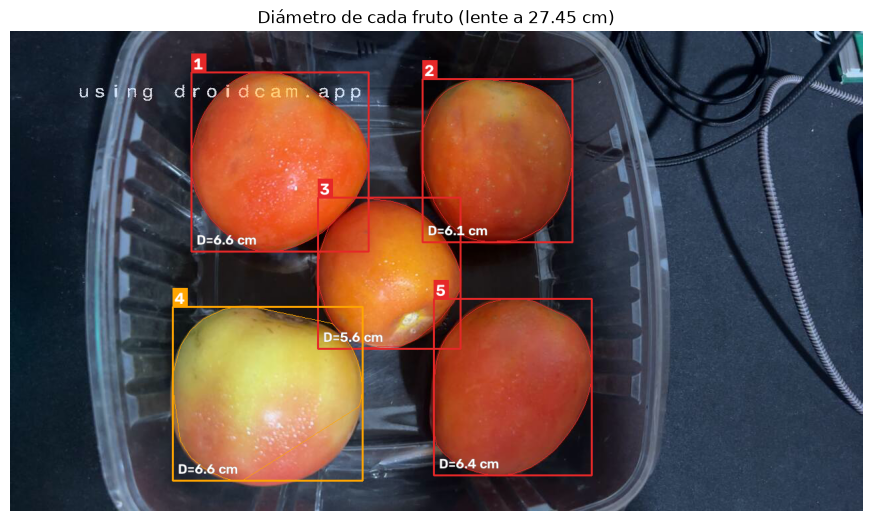

,id,categoria,tamano_relativo,diametro_equiv_px,profundidad_mm,ancho_mm,alto_mm,diametro_equiv_mm
0,1,Maduro,Mediano,260.874,241.709,66.871,67.625,65.582
1,2,Maduro,Mediano,238.728,244.185,57.143,62.223,60.630
2,3,Maduro,Pequeño,216.628,246.707,54.911,58.247,55.585
3,4,Pintón,Mediano,263.664,241.400,71.556,65.530,66.199
4,5,Maduro,Mediano,251.898,242.706,59.826,66.895,63.587


In [20]:
def analizar_par_metrico(img_i, img_d, cal, sgbm, nombre):
    rect = est.calcular_rectificacion(cal)
    ri, rd = est.rectificar_par(img_i, img_d, rect)
    disp = est.calcular_disparidad(ri, rd, sgbm)
    pts = est.nube_3d(disp, rect.Q)
    z_val = pts[..., 2][np.isfinite(pts[..., 2])]
    if len(z_val) and np.median(z_val) < 0:
        print("AVISO: profundidades negativas -> izquierda/derecha invertidas. Se descarta.")
        return None
    res_r = seg.segmentar(ri, PARAMS)
    df_r = clas.aplicar_reglas(car.extraer_caracteristicas(res_r, REGLAS), REGLAS)
    if df_r.empty:
        print("No se detectaron frutos en la imagen izquierda rectificada.")
        return None
    med = est.medir_tomates(df_r, res_r.detecciones, res_r.escala, pts, rect.f_px)
    df_r = df_r.merge(med, on="id")
    # Dibujo con profundidad y diámetro
    vista = vis.dibujar_detecciones(res_r.imagen, res_r.detecciones, df_r, REGLAS)
    for d in res_r.detecciones:
        f = df_r.loc[df_r["id"] == d.id].iloc[0]
        txt = "sin Z" if np.isnan(f["profundidad_mm"]) else \
            f"Z={f['profundidad_mm'] / 10:.0f}cm D={f['diametro_equiv_mm'] / 10:.1f}cm"
        x, y, w, h = d.bbox
        cv2.putText(vista, txt, (x, y + h + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
    vis.mostrar_grilla([vista, vis.mapa_disparidad_color(disp)],
                       [f"{nombre}: profundidad y tamaño", "Disparidad"], columnas=2, tam_celda=8)
    plt.show()
    proc.guardar_imagen(cfg.DIR_RES_DISPARIDAD / f"{nombre}_disparidad.png", vis.mapa_disparidad_color(disp))
    proc.guardar_imagen(cfg.DIR_RES_DETECCIONES / f"{nombre}_profundidad.png", vista)
    return df_r

df_metrico = None
if ALTURA_CELULAR_CM and len(df):
    h_o, w_o = img.shape[:2]          # los píxeles medidos son los de la imagen de trabajo
    f_foto = est.calibracion_por_fov((max(w_o, h_o), min(w_o, h_o)),
                                     est.fov_horizontal_desde_f35(cfg.F35_CELULAR)).K[0, 0]
    df_metrico = df.merge(est.medir_por_altura(df, ALTURA_CELULAR_CM * 10, f_foto), on="id")
    img_medidas = vis.dibujar_diametros(img_clasif, res.detecciones, df_metrico)
    plt.figure(figsize=(11, 7)); plt.imshow(proc.a_rgb(img_medidas)); plt.axis("off")
    plt.title(f"Diámetro de cada fruto (lente a {ALTURA_CELULAR_CM:g} cm)"); plt.show()
    proc.guardar_imagen(cfg.DIR_RES_DETECCIONES / f"{NOMBRE}_medidas.png", img_medidas)
elif cal_est_m3 is not None:
    df_metrico = analizar_par_metrico(izq_m3, der_m3, cal_est_m3, SGBM, ri_path.stem)
elif cal_est_m2 is not None:
    df_metrico = analizar_par_metrico(izq_m2, der_m2, cal_est_m2, SGBM, f"m2_{ruta_i.stem}")

if df_metrico is not None:
    display(df_metrico[[c for c in ("id", "categoria", "tamano_relativo", "diametro_equiv_px", "frac_disparidad_valida",
                                    "profundidad_mm", "ancho_mm", "alto_mm", "diametro_equiv_mm")
                        if c in df_metrico]])
    df_metrico.to_csv(cfg.DIR_RES_ESTADISTICAS / "medidas_metricas.csv", index=False, encoding="utf-8-sig")
else:
    print("PENDIENTE — Indique ALTURA_CELULAR_CM en la Etapa 1 para medir en cm. Por ahora, tamaños en píxeles:")
    display(df[["id", "categoria", "diametro_equiv_px", "diametro_equiv_px_orig",
                "ancho_bbox_px", "alto_bbox_px"]] if len(df) else df)

---
# Etapa 8 — Integración, visualización y evaluación

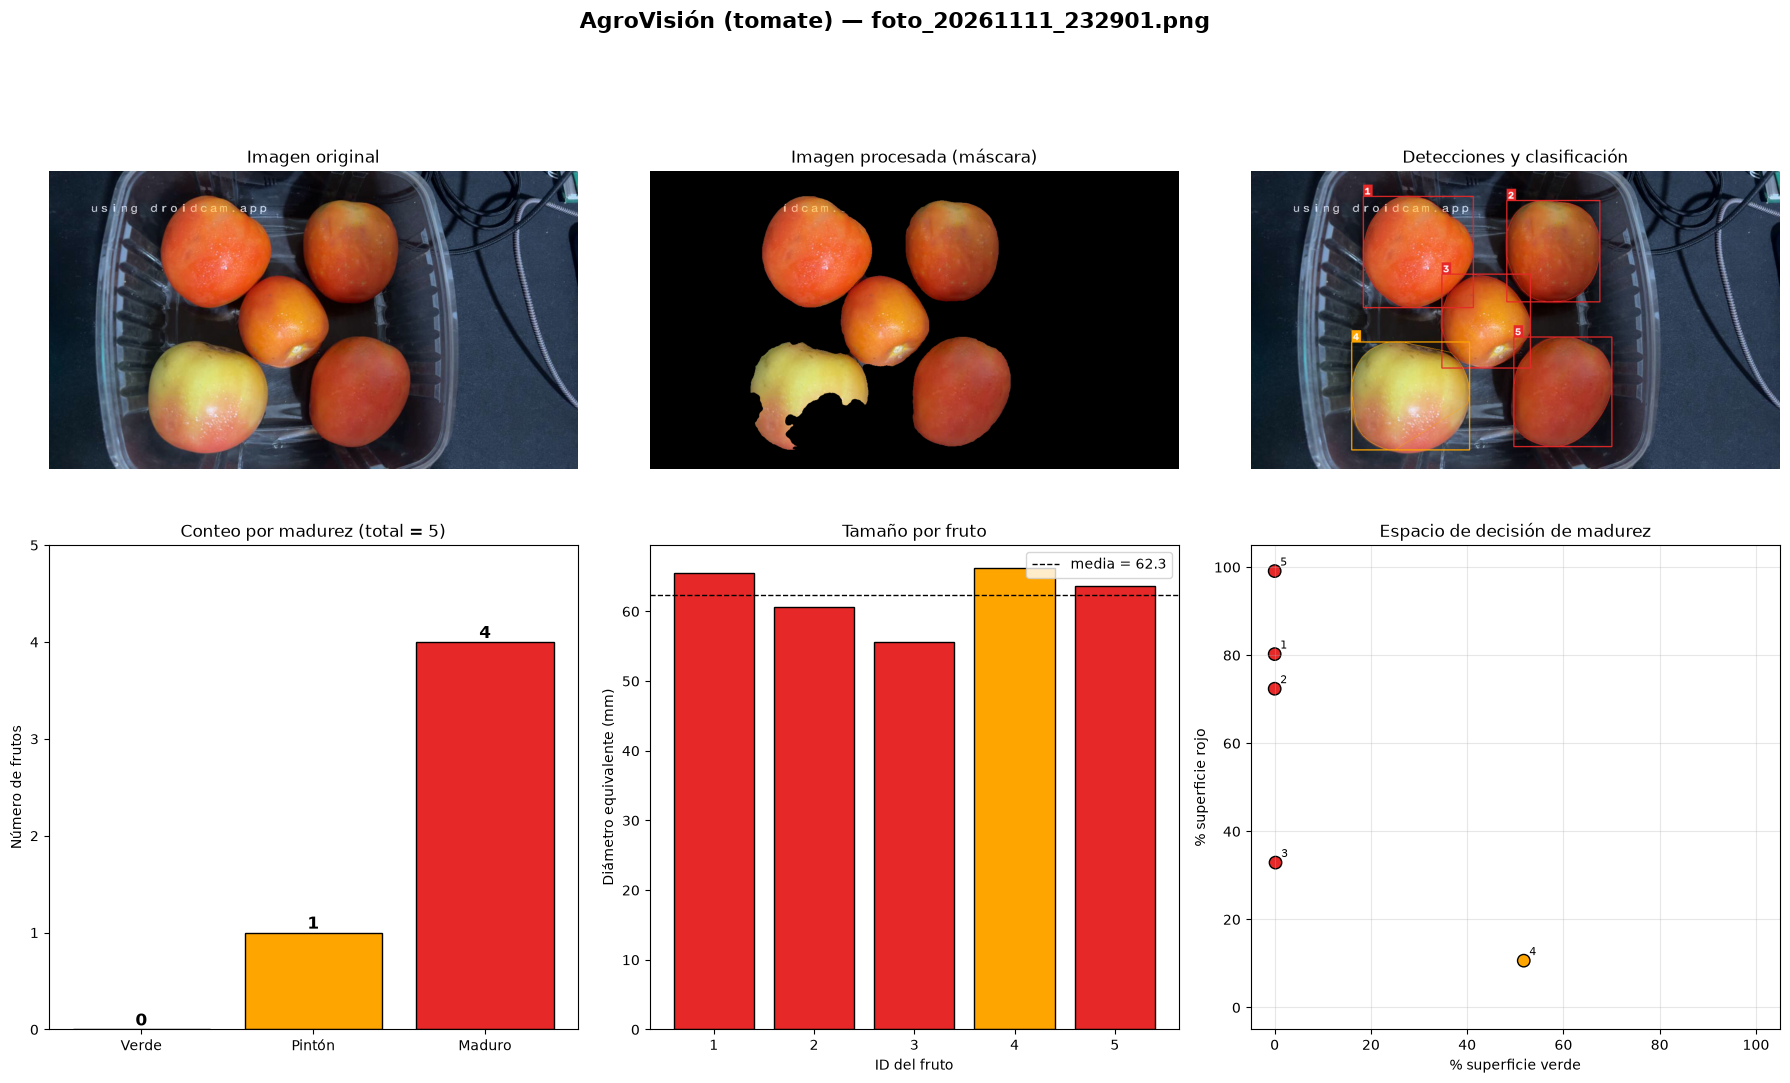

,valor
Fruta,tomate
Frutos detectados,5
Verde,0
Pintón,1
Maduro,4
Diámetro medio (px),246.358
Diámetro medio (mm),62.317
Profundidad media (mm),243.342


In [21]:
hay_mm = df_metrico is not None and df_metrico["diametro_equiv_mm"].notna().any()
df_panel = df_metrico if hay_mm else df
fig = vis.panel_resultados(
    img_original=img, img_procesada=img_segmentada, img_detecciones=img_clasif, df=df_panel, reglas=REGLAS,
    columna_tam="diametro_equiv_mm" if hay_mm else "diametro_equiv_px",
    etiqueta_tam="Diámetro equivalente (mm)" if hay_mm else "Diámetro equivalente (px) — sin calibración",
    titulo=f"AgroVisión ({PERFIL.nombre}) — {RUTA_IMAGEN.name}")
fig.savefig(cfg.DIR_RES_ESTADISTICAS / f"{NOMBRE}_panel.png", dpi=120, bbox_inches="tight")
plt.show()

resumen = pd.DataFrame({
    "Fruta": [PERFIL.nombre],
    "Frutos detectados": [len(df)],
    **{f"{c}": [int((df["categoria"] == c).sum()) if len(df) else 0] for c in REGLAS.categorias},
    "Diámetro medio (px)": [df["diametro_equiv_px"].mean() if len(df) else np.nan],
    "Diámetro medio (mm)": [df_metrico["diametro_equiv_mm"].mean() if hay_mm else "pendiente"],
    "Profundidad media (mm)": [df_metrico["profundidad_mm"].mean() if hay_mm else "pendiente"],
})
display(resumen.T.rename(columns={0: "valor"}))

### 8.1 Evaluación

Cada métrica se calcula **solo si existe la referencia real**:

| Métrica | Referencia necesaria |
|---|---|
| Error de conteo | `CONTEO_MANUAL` (contar a mano los frutos de la foto) |
| Precisión / recall / F1 de detección (IoU ≥ 0.5) | `data/anotaciones_cajas.csv`: `imagen,x,y,w,h,categoria` (píxeles de la imagen original) |
| Exactitud y matriz de confusión | `categoria_real` en `data/etiquetas_madurez_<fruta>.csv` |
| Error de tamaño / profundidad | `data/medidas_reales.csv`: `imagen,id,diametro_real_mm,profundidad_real_mm` |
| Tiempo de procesamiento | Siempre (medido en esta ejecución) |

In [22]:
CONTEO_MANUAL = None     # <-- número de frutos contados a mano en la foto evaluada (None = no medir el error)
if CONTEO_MANUAL is not None:
    display(pd.DataFrame([ev.error_conteo(len(df), CONTEO_MANUAL)]))
else:
    print("Error de conteo: PENDIENTE (indique CONTEO_MANUAL).")

# Precisión y recall de detección
if cfg.ARCHIVO_ANOTACIONES.exists():
    anot = pd.read_csv(cfg.ARCHIVO_ANOTACIONES, encoding="utf-8-sig")
    anot = anot[anot["imagen"] == RUTA_IMAGEN.name]
    if len(anot):
        gt = [tuple(int(round(v * escala)) for v in f) for f in anot[["x", "y", "w", "h"]].to_numpy()]
        pr = ev.precision_recall([d.bbox for d in res.detecciones], gt, 0.5)
        display(pd.DataFrame([{k: v for k, v in pr.items() if k != "emparejamientos"}]))
        # Madurez: cada fruto detectado se compara con la etapa anotada en su caja real.
        if "categoria" in anot.columns and pr["emparejamientos"]:
            cat_pred = dict(zip(df["id"], df["categoria"]))
            reales = [anot["categoria"].iloc[g] for _, g, _ in pr["emparejamientos"]]
            predichas = [cat_pred[res.detecciones[p].id] for p, _, _ in pr["emparejamientos"]]
            r_caja = ev.evaluar_clasificacion(reales, predichas, REGLAS.categorias)
            print(f"Madurez (reglas) vs etapa anotada en las cajas: exactitud {r_caja['exactitud']:.3f} "
                  f"(n={len(reales)} frutos detectados)")
            display(r_caja["matriz"])
    else:
        print(f"Detección: PENDIENTE (sin anotaciones para {RUTA_IMAGEN.name}).")
else:
    print("Precisión/recall: PENDIENTE (no existe data/anotaciones_cajas.csv).")

# Exactitud de clasificación de esta imagen
etq_img = df_etiq[df_etiq["imagen"] == RUTA_IMAGEN.name] if len(df_etiq) else df_etiq
if len(etq_img):
    unido = etq_img[["id", "categoria_real"]].merge(df[["id", "categoria"]], on="id")
    r_cls = ev.evaluar_clasificacion(unido["categoria_real"], unido["categoria"], REGLAS.categorias)
    print(f"Exactitud reglas en {RUTA_IMAGEN.name}: {r_cls['exactitud']:.3f} (n={len(unido)})")
    display(r_cls["matriz"])
    print(r_cls["reporte"])
else:
    print(f"Clasificación: PENDIENTE (complete categoria_real en {PERFIL.archivo_etiquetas.relative_to(cfg.RAIZ)}).")

# Error de tamaño y profundidad
if cfg.ARCHIVO_MEDIDAS_REALES.exists() and hay_mm:
    reales = pd.read_csv(cfg.ARCHIVO_MEDIDAS_REALES, encoding="utf-8-sig").merge(df_metrico, on="id")
    print("Tamaño:", ev.error_medidas(reales["diametro_equiv_mm"], reales["diametro_real_mm"]))
    print("Profundidad:", ev.error_medidas(reales["profundidad_mm"], reales["profundidad_real_mm"]))
else:
    print("Error de tamaño/profundidad: PENDIENTE (requiere medidas reales y calibración estéreo).")

# Tiempo de procesamiento (medición real de esta ejecución)
tiempos = crono.tabla()
display(tiempos)
tiempos.to_csv(cfg.DIR_RES_ESTADISTICAS / f"{NOMBRE}_tiempos.csv", index=False, encoding="utf-8-sig")

Error de conteo: PENDIENTE (indique CONTEO_MANUAL).
Detección: PENDIENTE (sin anotaciones para foto_20261111_232901.png).
Clasificación: PENDIENTE (complete categoria_real en data\etiquetas_madurez_tomate.csv).
Error de tamaño/profundidad: PENDIENTE (requiere medidas reales y calibración estéreo).


,etapa,tiempo_ms
0,1. carga,13.356
1,1. reconocer fruta,1776.964
2,1. redimensionado,0.805
3,2. preprocesamiento,12.414
4,3. segmentación + watershed + validación,78.813
5,4. características,29.477
6,4. clasificación por reglas,0.425
7,TOTAL,1912.254


### 8.2 Estado del sistema en esta ejecución

In [23]:
estado = pd.DataFrame([
    ("Perfil de fruta", PERFIL.nombre, ", ".join(REGLAS.categorias)),
    ("Modo 1 — detección, conteo y clasificación por reglas", "ejecutado", f"{len(df)} frutos en {RUTA_IMAGEN.name}"),
    ("Clasificador ML (SVM / k-NN / árbol)", "ejecutado" if tabla_cmp is not None else "pendiente de etiquetas",
     f"{len(df_etiq)} ejemplos etiquetados"),
    ("Modo 2 — par del celular", "cargado" if hay_par_m2 else "pendiente de fotos", ""),
    ("Modo 2 — calibración del celular (sin tablero)", "aproximada" if cal_cel is not None else "pendiente",
     cal_cel.vistas[0] if cal_cel is not None else ""),
    ("Modo 2 — rectificación + disparidad", ("calibrada" if cal_est_m2 is not None else "no calibrada (relativa)")
     if disp_m2 is not None else "pendiente", ""),
    ("Modo 3 — PC + celular (DroidCam, sin tablero)", "disponible" if cal_est_m3 is not None else "pendiente de captura",
     f"|T| = {cal_est_m3.linea_base_mm:.1f} mm" if cal_est_m3 is not None else ""),
    ("Profundidad y dimensiones físicas", "calculadas" if hay_mm else "pendiente de ALTURA_CELULAR_CM", ""),
], columns=["Componente", "Estado", "Detalle"])
display(estado)

,Componente,Estado,Detalle
0,Perfil de fruta,tomate,"Verde, Pintón, Maduro"
1,"Modo 1 — detección, conteo y clasificación por...",ejecutado,5 frutos en foto_20261111_232901.png
2,Clasificador ML (SVM / k-NN / árbol),pendiente de etiquetas,0 ejemplos etiquetados
3,Modo 2 — par del celular,pendiente de fotos,
4,Modo 2 — calibración del celular (sin tablero),pendiente,
5,Modo 2 — rectificación + disparidad,pendiente,
6,"Modo 3 — PC + celular (DroidCam, sin tablero)",pendiente de captura,
7,Profundidad y dimensiones físicas,calculadas,
